In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']

In [3]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [4]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [5]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [6]:
def get_eff2(df):
    true = np.histogram(df['pt'], bins=binedges, weights=df['w'])[0]
    match = np.histogram(df[df.pts>15]['pt'], bins=binedges, weights=df[df.pts>15]['w'])[0]
    return match/true

In [7]:
def get_eff3(df):
    true = np.histogram(df['pt'], bins=binedges, weights=df['w'])[0]
    match = np.histogram(df[(df.pts>15) & (df.bs!=-9)]['pt'], bins=binedges, weights=df[(df.pts>15) & (df.bs!=-9)]['w'])[0]
    return match/true

In [8]:
def get_eff4(df):
    true = np.histogram(df['pt'], bins=binedges, weights=df['w'])[0]
    match = np.histogram(df[(df.pts>15) & (df.bs!=-9) & (df.distance1<0.02) & (df.distance2<0.02)]['pt'], bins=binedges, weights=df[(df.pts>15) & (df.bs!=-9) & (df.distance1<0.02) & (df.distance2<0.02)]['w'])[0]
    return match/true

In [9]:
df = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.root', "MatchedTree"),\
              'pt>15 and b!=-9')

In [10]:
df.shape[0]

5922071

In [11]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [12]:
binedges=[15,20,25,30,40,60]
x=[17.5,22.5,27.5,35,50]

In [13]:
df_os = applyCut(df, 'b==-1')
df_ss = applyCut(df, 'b==1')

In [14]:
plt.rcParams['font.size'] = 12

[0.23001244 0.4458641  0.52890638 0.56108629 0.53124013]
[0.22435141 0.44945863 0.53269602 0.55840254 0.53416639]


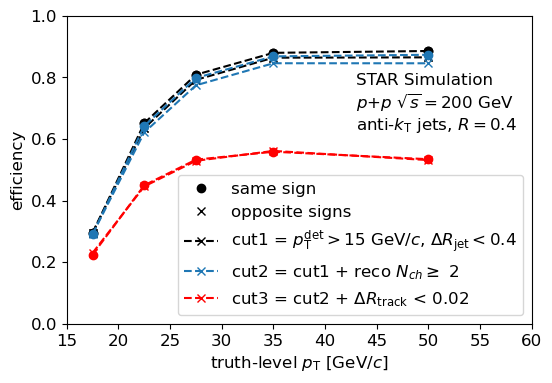

In [16]:
fig = plt.figure(figsize=(6,4))
plt.plot(x, get_eff2(df_ss), 'o', color='k', ls='none', label='same sign')
plt.plot(x, get_eff2(df_os), 'x', color='k', ls='none', label='opposite signs')
plt.plot(x, get_eff2(df_os), 'x--', color='k', label='cut1 = $p_{\mathrm{T}}^{\mathrm{det}}>15$ GeV$/c$, $\Delta R_{\mathrm{jet}}<0.4$')
plt.plot(x, get_eff3(df_os), 'x--', color='tab:blue', label=r'cut2 = cut1 + reco $N_{ch} \geq$ 2')
plt.plot(x, get_eff4(df_os), 'x--', color='r', label='cut3 = cut2 + $\Delta R_{\mathrm{track}}$ < 0.02')
plt.plot(x, get_eff2(df_ss), 'o--', color='k')
plt.plot(x, get_eff3(df_ss), 'o--', color='tab:blue')
plt.plot(x, get_eff4(df_ss), 'o--', color='r')
plt.xlabel(r'truth-level $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('efficiency')
plt.text(43, 0.63, 'STAR Simulation\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')
plt.legend()
plt.xlim(15,60)
plt.ylim(0.,1)
print(get_eff4(df_os))
print(get_eff4(df_ss))